In [1]:
#@title { display-mode: "form" }
from IPython.display import HTML, display

display(HTML(r'''
<div style="padding:28px 30px; border:1px solid #d6e6ff; border-radius:24px; background:linear-gradient(180deg,#f8fbff 0%,#f1f7ff 100%);">
  <div style="display:flex;align-items:flex-start;justify-content:space-between;gap:20px;margin-bottom:10px;">
  <div style="display:inline-block; margin-bottom:0; padding:6px 12px; border-radius:999px; background:rgba(36,94,168,0.10); border:1px solid rgba(36,94,168,0.16); color:#245ea8; font-size:12px; font-weight:700; letter-spacing:0.04em; text-transform:uppercase;">AI культура · трек 2 · занятие 4</div>
    <a href="https://nexign.com/ru" target="_blank" rel="noopener" title="Nexign" style="display:block;flex:0 0 auto;text-decoration:none;line-height:1;">
      <img src="https://storage.yandexcloud.net/lms-itmo-ru-files-27a87tyf/AI%20Culture/QualifiedCustomer/lesson04/Logo_Nexign_Green.svg" alt="Nexign" style="display:block;width:108px;height:auto;border:0;">
    </a>
  </div>
  <h1 style="margin:0 0 12px; font-size:30px; line-height:1.18; color:#16385f;"><strong>Занятие 4. Конспект в блокноте</strong></h1>
  <p style="margin:0; font-size:17px; color:#4f6f96; max-width:920px;">Разбираем форму распределения числового признака, правостороннюю асимметрию и варианты логарифмирования.</p>
</div>
'''))

In [1]:
#@title { display-mode: "form" }
from IPython.display import HTML, display

display(HTML(r'''
<div style="margin:18px 0; padding:18px 20px; border:1px solid #d6e6ff; border-radius:18px; background:#ffffff;">
  <div style="font-size:12px; font-weight:700; text-transform:uppercase; letter-spacing:0.04em; color:#245ea8; margin-bottom:8px;">Как работать с блокнотом</div>
  <div style="font-size:15px; line-height:1.55; color:#2b2b2b;">Запускайте ячейки сверху вниз. После примеров с зарплатами зафиксируйте: как соотносятся среднее и медиана, есть ли правый хвост и какой вариант логарифмирования подходит для признака.</div>
</div>
'''))

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 140)
plt.rcParams['figure.figsize'] = (10, 4)

BASE_URL = "https://storage.yandexcloud.net/lms-itmo-ru-files-27a87tyf/AI%20Culture/QualifiedCustomer/lesson04"

def read_lesson_csv(filename):
    local_path = Path(filename)
    source = local_path if local_path.exists() else f"{BASE_URL}/{filename}"
    return pd.read_csv(source)

## Цель занятия

Научиться готовить очищенные данные к машинному обучению:

```text
Cleaned Dataset → структура и типы → числовые признаки → категориальные признаки → даты и пропуски → масштабирование → проверка → Machine-Ready Dataset
```
**Главная идея:** разные типы данных требуют разных преобразований. Подготовка данных заканчивается тогда, когда признаки представлены в формате, с которым может работать выбранный алгоритм.


## 1. Изучаем датасет

Перед преобразованием данных сначала нужно понять, **что находится в датасете**.

Проверим:

* размер датасета;
* названия признаков;
* типы данных;
* наличие пропусков;
* основные статистики числовых признаков.

Это позволяет обнаружить проблемы ещё **до начала преобразований**.


In [3]:
#@title Подготовка дополнительных учебных файлов { display-mode: "form" }
from pathlib import Path
from urllib.parse import quote
from urllib.request import urlretrieve

_EXTRA_DATA_BASE = "https://storage.yandexcloud.net/lms-itmo-ru-files-27a87tyf/AI%20Culture/QualifiedCustomer/lesson04"
_EXTRA_DATA_FILES = ["CustomerPurchaseDataset.csv", "Loan_approval_data_2025.csv"]
for _filename in _EXTRA_DATA_FILES:
    _path = Path(_filename)
    if not _path.exists():
        urlretrieve(f"{_EXTRA_DATA_BASE}/{quote(_filename)}", _filename)
        print(f"Загружен {_filename}")

Загружен CustomerPurchaseDataset.csv
Загружен Loan_approval_data_2025.csv


### Знакомимся с данными

Перед анализом важно понимать, **что означает каждый признак**.

Мы будем работать с данными о поведении покупателей и их покупках. Каждый объект соответствует одному наблюдению о клиенте и его сессии.

| Признак              | Описание                            | Тип            |
| -------------------- | ----------------------------------- | -------------- |
| `country`            | страна клиента                      | категориальный |
| `device_type`        | тип устройства                      | категориальный |
| `education`          | уровень образования                 | категориальный |
| `membership`         | уровень членства                    | категориальный |
| `gender`             | пол клиента                         | категориальный |
| `is_returning`       | вернулся ли клиент на сайт повторно | бинарный       |
| `has_newsletter`     | подписан ли клиент на рассылку      | бинарный       |
| `age`                | возраст клиента                     | числовой       |
| `session_duration`   | продолжительность сессии            | числовой       |
| `satisfaction_score` | оценка удовлетворённости            | числовой       |
| `pages_visited`      | количество просмотренных страниц    | числовой       |
| `cart_items`         | количество товаров в корзине        | числовой       |
| `discount_used`      | размер использованной скидки        | числовой       |
| `total_spent`        | общая сумма покупок                 | числовой       |
| `purchase_made`      | была ли совершена покупка           | бинарный       |

> **Важно:** тип хранения в Pandas и смысл признака — не одно и то же. Например, `is_returning` хранится как `int64`, но по смыслу это бинарный признак.


In [4]:
df = read_lesson_csv("CustomerPurchaseDataset.csv")

df.head()

,country,device_type,education,membership,gender,is_returning,has_newsletter,age,session_duration,satisfaction_score,pages_visited,cart_items,discount_used,total_spent,purchase_made
0,UK,Desktop,Bachelor,Silver,F,0,1,33,10.2,3.5,5,4,16.2,5875.90,0
1,Canada,Mobile,Bachelor,Gold,M,0,0,39,7.0,3.0,8,2,7.9,1566.68,1
2,Brazil,Tablet,High School,Silver,M,1,1,29,13.1,3.6,8,2,28.3,1141.96,0
3,France,Desktop,Bachelor,Bronze,F,1,0,41,4.6,2.9,4,0,20.9,1392.40,0
4,USA,Tablet,Bachelor,Bronze,F,1,0,28,50.7,3.9,8,1,29.3,1301.10,1


### Посмотрим структуру данных

Начнём с простого первичного осмотра:

* сколько в датасете строк и столбцов;
* какие признаки представлены;
* какие типы данных используются;
* есть ли пропуски.


In [5]:
print("Размер датасета:", df.shape)
print("\nПризнаки:")
print(df.columns.tolist())

print("\nТипы данных и пропуски:")
df.info()

Размер датасета: (5000, 15)

Признаки:
['country', 'device_type', 'education', 'membership', 'gender', 'is_returning', 'has_newsletter', 'age', 'session_duration', 'satisfaction_score', 'pages_visited', 'cart_items', 'discount_used', 'total_spent', 'purchase_made']

Типы данных и пропуски:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   country             5000 non-null   str    
 1   device_type         5000 non-null   str    
 2   education           5000 non-null   str    
 3   membership          5000 non-null   str    
 4   gender              5000 non-null   str    
 5   is_returning        5000 non-null   int64  
 6   has_newsletter      5000 non-null   int64  
 7   age                 5000 non-null   int64  
 8   session_duration    5000 non-null   float64
 9   satisfaction_score  5000 non-null   float64
 10  pages_visited       

### Посмотрим на статистику

Для числовых признаков полезно посмотреть основные статистики:

* количество наблюдений;
* среднее значение;
* стандартное отклонение;
* минимальное и максимальное значения;
* квартили.

Они помогают быстро заметить **необычные значения и подозрительно широкий диапазон**.


In [6]:
df.describe()

,is_returning,has_newsletter,age,session_duration,satisfaction_score,pages_visited,cart_items,discount_used,total_spent,purchase_made
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.641600,0.404200,38.647800,19.558940,3.836266,5.981000,2.952200,14.811840,1964.888606,0.485600
std,0.479578,0.490786,13.618489,41.730242,0.698622,2.412593,8.194177,8.595992,7360.810678,0.499843
min,0.000000,0.000000,18.000000,0.800000,-0.927685,1.000000,0.000000,0.000000,47.770000,0.000000
25%,0.000000,0.000000,30.000000,7.000000,3.400000,4.000000,1.000000,7.400000,597.140000,0.000000
50%,1.000000,0.000000,38.000000,12.100000,3.900000,6.000000,2.000000,14.700000,1099.630000,0.000000
75%,1.000000,1.000000,46.000000,20.925000,4.400000,7.000000,4.000000,22.200000,1963.012500,1.000000
max,1.000000,1.000000,149.000000,593.764631,5.000000,21.000000,196.000000,30.000000,198342.202196,1.000000


### Что можно заметить?

Посмотрите на таблицу статистик.

Обратите внимание на признаки, у которых минимальное или максимальное значение выглядит необычно;

**Какие значения стоит проверить дополнительно?**


In [8]:
print("Медиана total_spent:", df["total_spent"].median())
print("Максимум total_spent:", df["total_spent"].max())

print("\nМаксимальный возраст:", df["age"].max())

Медиана total_spent: 1099.63
Максимум total_spent: 198342.20219583125

Максимальный возраст: 149


Но необычное значение не обязательно является ошибкой.

Большая сумма покупки может принадлежать VIP-клиенту, а необычный возраст может быть результатом ошибки ввода.

Статистика помогает найти подозрительные значения, но сама по себе не говорит, являются ли они ошибками.

### Какие типы данных встречаются в Pandas?

Признаки в датасете могут храниться в разных типах.

| Тип                 | Что хранит              | Пример              |
| ------------------- | ----------------------- | ------------------- |
| `int64`             | целые числа             | возраст             |
| `float64`           | вещественные числа      | сумма покупки       |
| `object` / `string` | текст                   | город               |
| `bool`              | логические значения     | `True` / `False`    |
| `datetime64`        | даты и время            | дата заказа         |
| `category`          | категориальные значения | уровень образования |

> **Важно:** `object` — это тип хранения, а не отдельный тип признака. Например, текстовые категории часто находятся в столбце типа `object`.


In [7]:
df.dtypes

country                   str
device_type               str
education                 str
membership                str
gender                    str
is_returning            int64
has_newsletter          int64
age                     int64
session_duration      float64
satisfaction_score    float64
pages_visited           int64
cart_items              int64
discount_used         float64
total_spent           float64
purchase_made           int64
dtype: object

In [8]:
df.dtypes.value_counts()

int64      6
str        5
float64    4
Name: count, dtype: int64

### Почему важно проверять типы?

Значение может выглядеть правильно для человека, но храниться в неправильном типе.

Например:

```text
"25"   → строка
25     → число
```

Внешне они похожи, но Python обрабатывает их по-разному.

Если возраст хранится как текст, мы не сможем корректно выполнять над ним числовые операции и использовать его как числовой признак.

> **Перед преобразованием данных важно проверить не только сами значения, но и их типы.**


In [9]:
#сгенерированный пример
age_example = pd.Series(["25", "31", "42", "28"])

print(age_example)
print("Тип:", age_example.dtype)

0    25
1    31
2    42
3    28
dtype: str
Тип: str


In [10]:
age_example = pd.to_numeric(age_example)

print(age_example)
print("Тип:", age_example.dtype)

0    25
1    31
2    42
3    28
dtype: int64
Тип: int64


### Преобразование типов

Если тип признака не соответствует его содержанию, его можно изменить.

Например:

* `astype()` — когда мы точно знаем, какой тип нужен;
* `pd.to_numeric()` — для преобразования значений в числа;
* `pd.to_datetime()` — для преобразования дат.

Выбор способа зависит от содержания конкретного столбца.


In [11]:
# Примеры преобразования типов
df["is_returning"] = df["is_returning"].astype(bool)
df["has_newsletter"] = df["has_newsletter"].astype(bool)

### Работа с датами

Дата — это особый тип признака.

Если дата хранится как обычный текст, Python не воспринимает её как дату и не может напрямую выполнять операции с годом, месяцем или днем недели.

Поэтому сначала преобразуем её в `datetime`.


Если столбец содержит даты, его также необходимо привести к специальному типу.

Например,

`df["hire_date"] = pd.to_datetime(df["hire_date"])`

После этого становятся доступны операции:

`df["hire_date"].dt.year`

`df["hire_date"].dt.month`

`df["hire_date"].dt.dayofweek`



### Дата — это не только тип данных

После преобразования даты мы можем извлечь из неё признаки, которые могут быть полезны модели:

```text
2025-03-17
     ↓
год       → 2025
месяц     → 3
день недели → понедельник
```

Какие именно признаки извлекать, зависит от задачи.

Например, для анализа сезонности может быть важен месяц, а для анализа рабочего графика — день недели.

> **Подготовка данных — это не только исправление типа. Иногда нужно изменить представление исходного признака так, чтобы сохранить полезную для модели информацию.**


## 2. Числовые признаки

В предыдущем разделе мы посмотрели на структуру датасета и определили типы признаков.

Теперь рассмотрим **числовые признаки**. Для них важно понять:

* как распределены значения;
* есть ли сильная асимметрия;
* встречаются ли необычно большие или маленькие значения;
* требуется ли преобразование признака.

> **Практический принцип:** сначала анализируем признак → затем решаем, нужно ли его преобразовывать.


In [12]:
#находим числовые признаки
numeric_columns = df.select_dtypes(include="number").columns

print("Числовые признаки:")
print(numeric_columns.tolist())

Числовые признаки:
['age', 'session_duration', 'satisfaction_score', 'pages_visited', 'cart_items', 'discount_used', 'total_spent', 'purchase_made']


is_returning, has_newsletter и purchase_made хранятся как int64, хотя по смыслу являются бинарными признаками.

In [13]:
binary_columns = ["is_returning", "has_newsletter", "purchase_made"]

continuous_columns = [
    col for col in numeric_columns
    if col not in binary_columns
]

print("Количественные числовые признаки:")
print(continuous_columns)

Количественные числовые признаки:
['age', 'session_duration', 'satisfaction_score', 'pages_visited', 'cart_items', 'discount_used', 'total_spent']


**Тип int64 ещё не говорит, что признак является количественным. Нужно учитывать смысл признака.**

### Зачем анализировать распределение признаков?

Для числового признака важно посмотреть, **как распределены его значения**.

Распределение помогает понять:

* где сосредоточено большинство значений;
* насколько велик разброс;
* есть ли асимметрия;
* есть ли длинный хвост;
* встречаются ли необычные значения;
* не скрываются ли за несколькими пиками разные группы объектов.

Это важно, потому что одни и те же числовые значения могут по-разному влиять на модель в зависимости от их распределения.

> **Распределение — это инструмент диагностики. Оно помогает решить, нужно ли дальнейшее преобразование признака.**


### Какие формы распределения важно замечать?

Для подготовки данных не обязательно определять точный теоретический закон распределения. В первую очередь достаточно научиться замечать несколько характерных форм:

| Форма                 | Что видим                                                         |
| --------------------- | ----------------------------------------------------------------- |
| **Симметричная**      | значения распределены примерно одинаково по обе стороны от центра |
| **Правая асимметрия** | основная масса значений слева, длинный хвост тянется вправо       |
| **Левая асимметрия**  | основная масса значений справа, длинный хвост тянется влево       |
| **Длинный хвост**     | небольшое количество сильно отличающихся значений                 |
| **Мультимодальная**   | несколько выраженных пиков                                        |

Наличие определённой формы **не означает автоматически, что признак нужно преобразовать**. Сначала нужно понять причину такой формы и требования выбранного алгоритма.


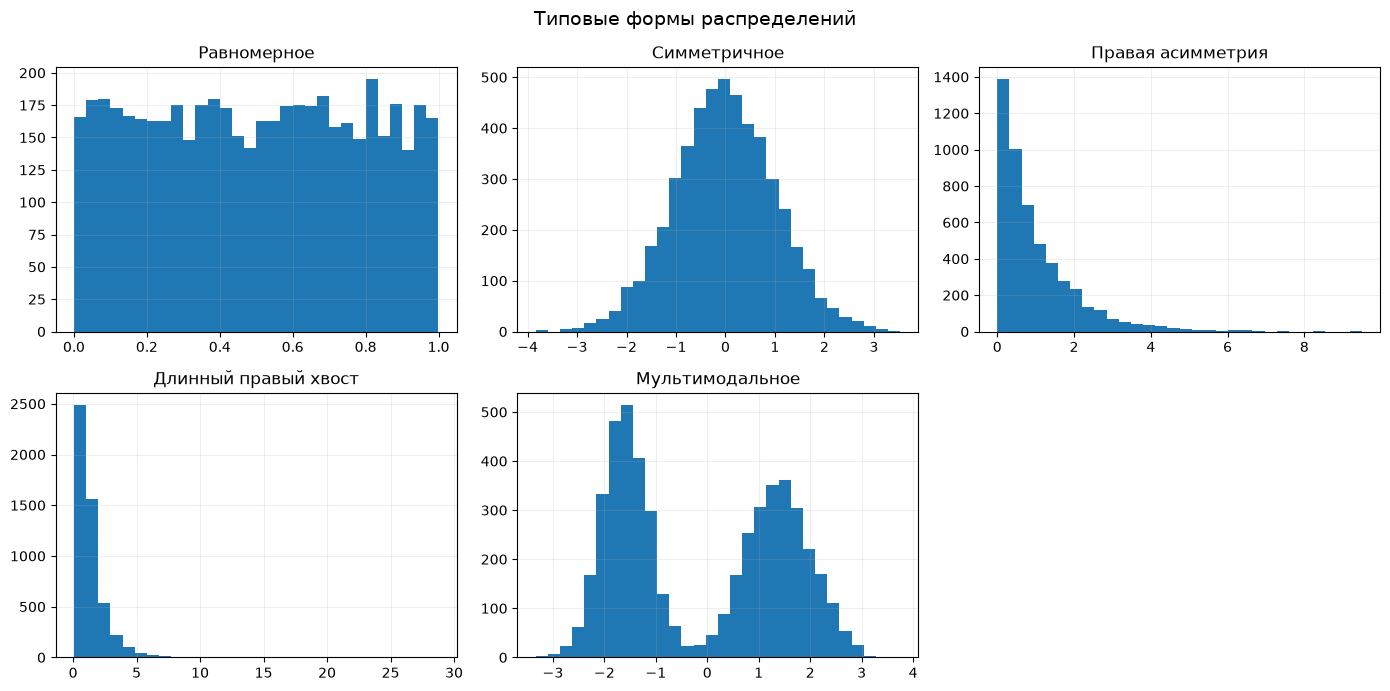

In [14]:
np.random.seed(42)

samples = {
    "Равномерное": np.random.uniform(0, 1, 5000),
    "Симметричное": np.random.normal(0, 1, 5000),
    "Правая асимметрия": np.random.exponential(scale=1.0, size=5000),
    "Длинный правый хвост": np.random.lognormal(mean=0.0, sigma=0.75, size=5000),
    "Мультимодальное": np.concatenate([
        np.random.normal(-1.6, 0.45, 2500),
        np.random.normal(1.4, 0.65, 2500)
    ])
}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax, (title, values) in zip(axes, samples.items()):
    ax.hist(values, bins=30)
    ax.set_title(title)
    ax.grid(alpha=0.2)

axes[-1].axis("off")

plt.suptitle("Типовые формы распределений", fontsize=14)
plt.tight_layout()
plt.show()

### Что можно понять по распределению?

Гистограмма позволяет сделать предварительный вывод о признаке и решить, нужно ли изучить его подробнее.

| Что видим                           | Что это может означать                                       | Что делать                                                   |
| ----------------------------------- | ------------------------------------------------------------ | ------------------------------------------------------------ |
| Примерно симметричное распределение | значения относительно равномерно сосредоточены вокруг центра | обычно оставить как есть                                     |
| Сильная правая асимметрия           | несколько больших значений растягивают правый хвост          | проверить значения; рассмотреть `log` или `sqrt`             |
| Сильная левая асимметрия            | несколько маленьких значений растягивают левый хвост         | проверить данные; при необходимости подобрать преобразование |
| Длинный хвост                       | возможны выбросы или редкие наблюдения                       | проверить происхождение значений                             |
| Несколько пиков                     | возможно, в данных смешаны разные группы                     | исследовать группы; не преобразовывать автоматически         |
| Почти все значения одинаковы        | признак может содержать мало полезной информации             | оценить, нужен ли он модели                                  |

> **Важно:** необычная форма распределения не означает, что данные плохие. Сначала выясняем причину, затем выбираем действие.


### Инсайт

**Не нужно делать каждое распределение «нормальным».**

Цель подготовки данных — не получить красивую гистограмму, а представить признак в форме, которая:

* сохраняет полезную информацию;
* соответствует смыслу данных;
* подходит выбранному алгоритму.

Поэтому последовательность всегда одна:

**увидели особенность → проверили данные → выбрали действие → проверили результат.**


### Посмотрим на распределения в нашем датасете

Теперь применим этот подход к реальным данным.

Начнём с количественных числовых признаков нашего датасета:

* `age`;
* `session_duration`;
* `satisfaction_score`;
* `pages_visited`;
* `cart_items`;
* `discount_used`;
* `total_spent`.

Построим для них гистограммы и посмотрим, какие особенности распределения можно обнаружить.


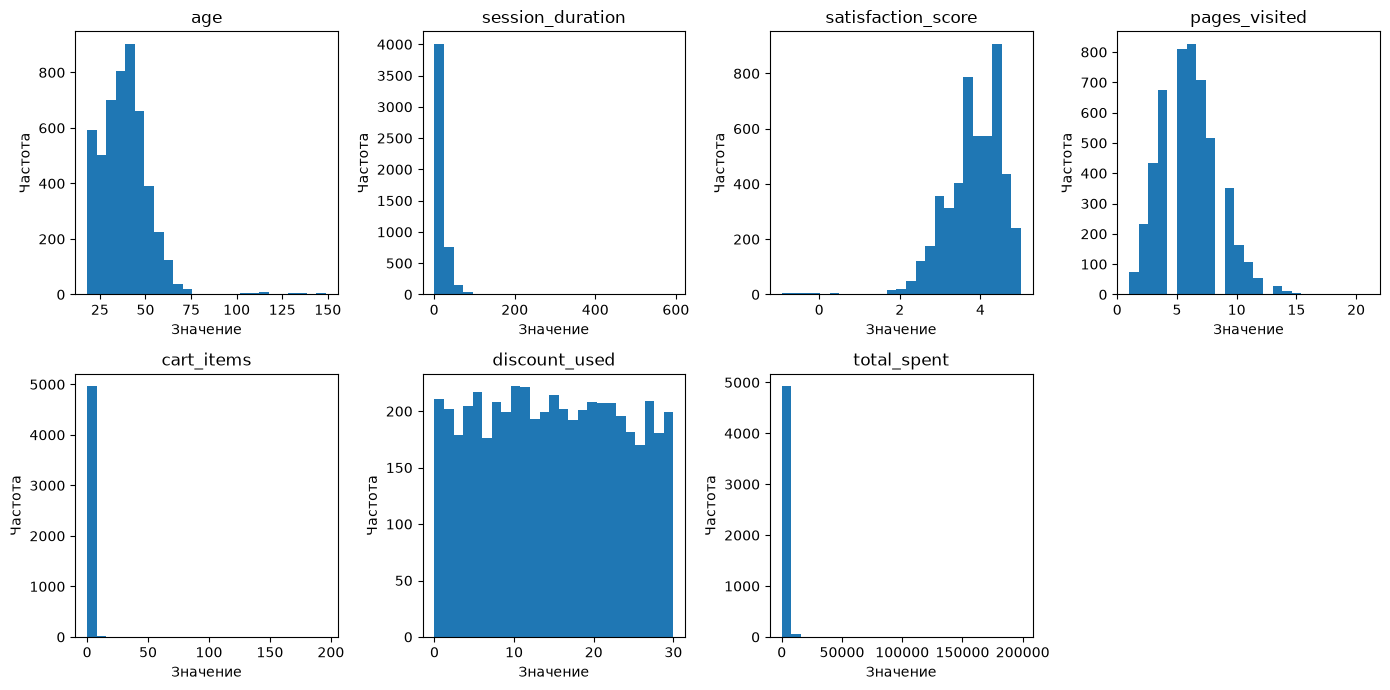

In [15]:
fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 7)
)

axes = axes.ravel()

for ax, column in zip(axes, continuous_columns):
    ax.hist(df[column].dropna(), bins=25)
    ax.set_title(column)
    ax.set_xlabel("Значение")
    ax.set_ylabel("Частота")

for ax in axes[len(continuous_columns):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Практический пример: правосторонняя асимметрия

Среди числовых признаков может встретиться распределение с длинным правым хвостом.

Рассмотрим отдельный небольшой датасет с зарплатами по регионам РФ. Он позволит подробно разобрать один типичный случай:

**правосторонняя асимметрия → диагностика → преобразование → повторная проверка.**

Мы будем:

1. смотреть базовые статистики;
2. строить гистограмму и boxplot;
3. сравнивать среднее и медиану;
4. применять логарифмирование;
5. сравнивать результат с исходным распределением.


In [16]:
salary_reg = read_lesson_csv("lesson04_salary_regions_rf.csv")

summary = pd.Series({
    "Количество регионов": len(salary_reg),
    "Среднее": round(salary_reg["salary"].mean(), 2),
    "Медиана": round(salary_reg["salary"].median(), 2),
    "Q1": round(salary_reg["salary"].quantile(0.25), 2),
    "Q3": round(salary_reg["salary"].quantile(0.75), 2),
    "IQR": round(
        salary_reg["salary"].quantile(0.75)
        - salary_reg["salary"].quantile(0.25),
        2
    ),
    "Минимум": int(salary_reg["salary"].min()),
    "Максимум": int(salary_reg["salary"].max())
})

display(salary_reg.head())
display(summary.to_frame("Значение"))

,region_name,salary
0,Алтайский край,25960
1,Амурская область,43156
2,Архангельская область,47526
3,Астраханская область,32166
4,Белгородская область,31163


,Значение
Количество регионов,85.0
Среднее,38831.8
Медиана,32973.0
Q1,28232.0
Q3,40728.0
IQR,12496.0
Минимум,24550.0
Максимум,101662.0


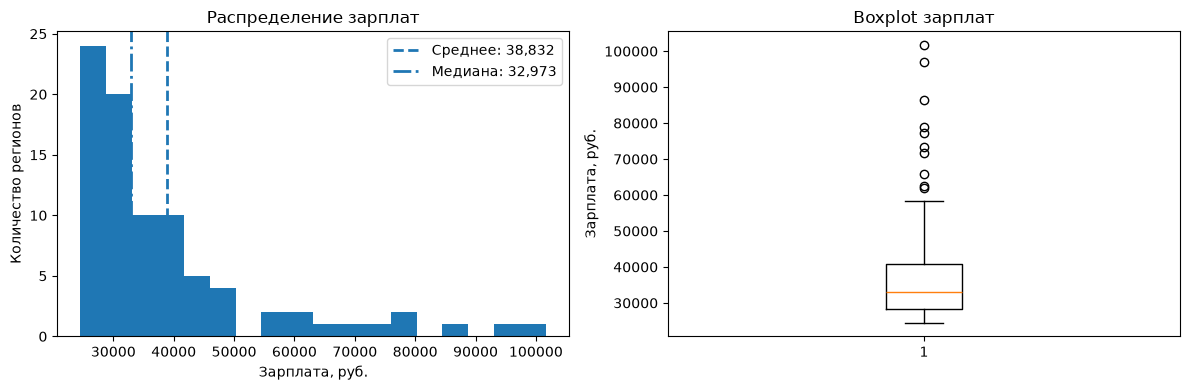

In [17]:
salary_mean = salary_reg["salary"].mean()
salary_median = salary_reg["salary"].median()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(salary_reg["salary"], bins=18)

ax[0].axvline(
    salary_mean,
    linestyle="--",
    linewidth=2,
    label=f"Среднее: {salary_mean:,.0f}"
)

ax[0].axvline(
    salary_median,
    linestyle="-.",
    linewidth=2,
    label=f"Медиана: {salary_median:,.0f}"
)

ax[0].set_title("Распределение зарплат")
ax[0].set_xlabel("Зарплата, руб.")
ax[0].set_ylabel("Количество регионов")
ax[0].legend()

ax[1].boxplot(salary_reg["salary"])
ax[1].set_title("Boxplot зарплат")
ax[1].set_ylabel("Зарплата, руб.")

plt.tight_layout()
plt.show()

### Что мы увидели?

На гистограмме видно, что основная масса зарплат сосредоточена в относительно узком диапазоне, а несколько регионов имеют значительно более высокие значения.

Это создаёт **правостороннюю асимметрию**.

Можно заметить, что:

* среднее выше медианы;
* большие значения заметно влияют на среднее;
* boxplot показывает более длинный верхний хвост и возможные нетипичные значения.

Такая ситуация — повод проверить, поможет ли преобразование уменьшить влияние длинного хвоста.


### Среднее, медиана и IQR

Для быстрой диагностики распределения полезно сравнить:

* **среднее** — учитывает все значения и поэтому чувствительно к экстремальным наблюдениям;
* **медиану** — центральное значение, менее чувствительное к экстремальным значениям;
* **IQR** — диапазон между первым и третьим квартилями.

При правой асимметрии несколько больших значений могут заметно увеличить среднее, поэтому часто наблюдается:

**среднее > медиана**

Boxplot объединяет эту информацию в одном графике:

* линия внутри коробки — медиана;
* границы коробки — Q1 и Q3;
* высота коробки — IQR;
* отдельные точки за «усами» — потенциально нетипичные наблюдения.


### Преобразуем признак

Для признаков с сильной правой асимметрией одним из возможных преобразований является **логарифмирование**.

Логарифм сильнее сжимает большие значения, чем маленькие:

```text
10    → 2.30
100   → 4.61
1000  → 6.91
```

Поэтому большие значения становятся ближе к основной массе наблюдений, а длинный правый хвост может уменьшиться.

Для разных значений признака используем:

| Условие                     | Преобразование                       |
| --------------------------- | ------------------------------------ |
| все значения > 0            | `np.log(x)`                          |
| возможны нули               | `np.log1p(x)`                        |
| есть отрицательные значения | простое логарифмирование не подходит |

После преобразования распределение **обязательно проверяем повторно**.


In [18]:
salary_reg["ln_salary"] = np.log(salary_reg["salary"])

comparison = pd.DataFrame({
    "Исходный salary": salary_reg["salary"].describe(),
    "После ln": salary_reg["ln_salary"].describe()
})

display(comparison)

,Исходный salary,После ln
count,85.000000,85.000000
mean,38831.800000,10.502238
std,16459.723565,0.336821
min,24550.000000,10.108467
25%,28232.000000,10.248211
50%,32973.000000,10.403444
75%,40728.000000,10.614671
max,101662.000000,11.529409


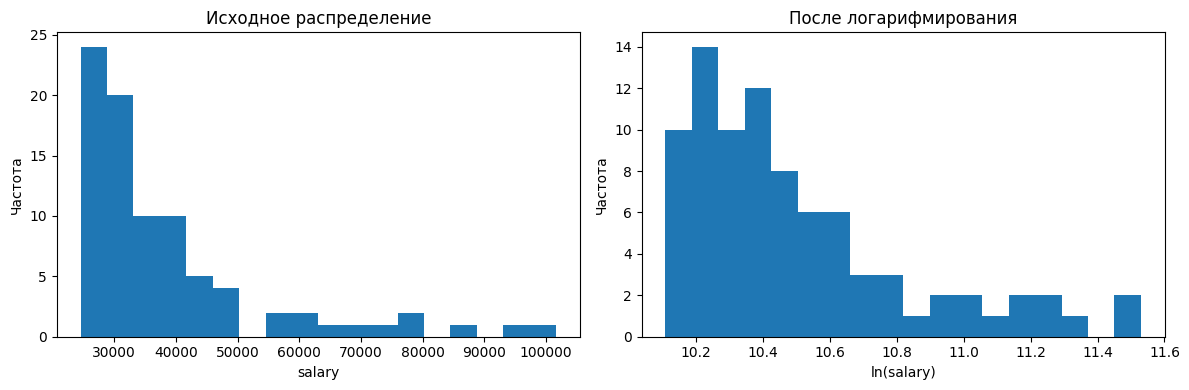

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(salary_reg["salary"], bins=18)
ax[0].set_title("Исходное распределение")
ax[0].set_xlabel("salary")
ax[0].set_ylabel("Частота")

ax[1].hist(salary_reg["ln_salary"], bins=18)
ax[1].set_title("После логарифмирования")
ax[1].set_xlabel("ln(salary)")
ax[1].set_ylabel("Частота")

plt.tight_layout()
plt.show()

### Какие преобразования можно использовать?

Логарифмирование — только один из способов изменить представление числового признака.

| Проблема                        | Возможное преобразование                         | Зачем                                                                    |
| ------------------------------- | ------------------------------------------------ | ------------------------------------------------------------------------ |
| Правосторонняя асимметрия       | `log`, `log1p`                                   | сильнее сжимает большие значения                                         |
| Умеренная правая асимметрия     | `sqrt`                                           | более мягко сжимает большие значения                                     |
| Сильная асимметрия разного типа | **Power Transform**                              | автоматически подбирает степень преобразования для уменьшения асимметрии |
| Выбросы                         | **clipping**                                     | ограничивает значения заданными границами                                |
| Выбросы                         | **winsorization**                                | заменяет крайние значения значениями выбранных процентилей               |
| Разные масштабы признаков       | `StandardScaler`, `MinMaxScaler`, `RobustScaler` | приводит признаки к сопоставимому масштабу                               |
| Несколько пиков                 | —                                                | сначала исследуем группы, а не применяем преобразование автоматически    |

**Важно:** эти методы решают разные задачи.

* `log` и `sqrt` изменяют **форму распределения**;
* `Power Transform` также изменяет форму распределения, подбирая подходящее преобразование;
* **clipping** ограничивает экстремальные значения заданным диапазоном;
* **winsorization** не удаляет выбросы, а заменяет крайние значения менее экстремальными;
* `StandardScaler`, `MinMaxScaler` и `RobustScaler` изменяют **масштаб**.

В этом занятии подробно рассмотрим логарифмирование, а остальные методы будем использовать как инструменты, которые можно выбрать в зависимости от ситуации.


### Вывод

В этом примере мы прошли полный цикл работы с числовым признаком:

**распределение → диагностика → преобразование → повторная проверка**

Мы увидели правостороннюю асимметрию, проверили статистики и попробовали логарифмирование.

Но логарифмирование — **не обязательный этап подготовки всех числовых признаков**.

В зависимости от ситуации можно:

* оставить признак без изменений;
* применить другое преобразование;
* обработать выбросы;
* использовать масштабирование;
* или вообще исключить признак, если он не содержит полезной информации.

> **Главный принцип:** сначала понять особенности числового признака, а затем выбрать подходящее действие.


## 3. Масштабирование

В предыдущем разделе мы рассматривали преобразования, которые могут менять **форму распределения** признака.

Теперь рассмотрим другую задачу — **масштабирование**.

> **Преобразование формы** меняет распределение признака, а **масштабирование** приводит значения к сопоставимой шкале.


### Зачем нужно масштабирование?

Даже после остальных преобразований числовые признаки могут иметь совершенно разные диапазоны:

| Признак  |       Диапазон |
| -------- | -------------: |
| Возраст  |          18–65 |
| Опыт     |           0–40 |
| Зарплата | 30 000–800 000 |

Для алгоритмов, которые используют **расстояния между объектами** или **градиентный спуск**, различия в масштабе могут влиять на результат.

Например, при вычислении расстояния `salary` с большими числовыми значениями может получить значительно больший вклад, чем `age`.

Поэтому числовые признаки часто приводят к сопоставимому масштабу.

> **Важно:** масштабирование не устраняет выбросы и не меняет смысл признака. Оно изменяет прежде всего **шкалу значений**.


### StandardScaler

`StandardScaler` стандартизирует признак относительно его среднего и стандартного отклонения:

$$
z = \frac{x-\mu}{\sigma}
$$

где:

* \(x\) — исходное значение;
* \(\mu\) — среднее значение признака;
* \(\sigma\) — стандартное отклонение.

После преобразования признак имеет **среднее около 0 и стандартное отклонение около 1**.


In [24]:
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()

df_standard = df.copy()

df_standard[continuous_columns] = standard_scaler.fit_transform(
    df[continuous_columns]
)

df_standard[continuous_columns].head()

,age,session_duration,satisfaction_score,pages_visited,cart_items,discount_used,total_spent
0,-0.414757,-0.224295,-0.481375,-0.406657,0.127884,0.161505,0.531382
1,0.025864,-0.300985,-1.197141,0.836943,-0.116216,-0.804157,-0.054104
2,-0.708505,-0.154794,-0.338222,0.836943,-0.116216,1.569279,-0.111810
3,0.172738,-0.358503,-1.340295,-0.821190,-0.360316,0.708326,-0.077783
4,-0.781942,0.746321,0.091238,0.836943,-0.238266,1.685624,-0.090188


In [28]:
df_standard[continuous_columns].describe().T[
    ["mean", "std", "min", "max"]
]

,mean,std,min,max
age,2.486900e-16,1.0001,-1.516311,8.103927
session_duration,-4.334311e-17,1.0001,-0.449574,13.761318
satisfaction_score,-2.430056e-16,1.0001,-6.819749,1.665923
pages_visited,2.984279e-17,1.0001,-2.064790,6.225876
cart_items,-1.776357e-18,1.0001,-0.360316,23.561499
discount_used,-1.385558e-17,1.0001,-1.723282,1.767065
total_spent,-4.618528e-18,1.0001,-0.260475,26.681430


Обратите внимание: средние значения признаков стали близки к 0, а стандартные отклонения — к 1.

При этом исходный df не изменился.

### MinMaxScaler

`MinMaxScaler` переводит значения в заданный диапазон. По умолчанию — от 0 до 1:

$$
x' = \frac{x-x_{\min}}{x_{\max}-x_{\min}}
$$

Минимальное значение признака становится 0, максимальное — 1.


In [25]:
from sklearn.preprocessing import MinMaxScaler

minmax_scaler = MinMaxScaler()

df_minmax = df.copy()

df_minmax[continuous_columns] = minmax_scaler.fit_transform(
    df[continuous_columns]
)

df_minmax[continuous_columns].head()

,age,session_duration,satisfaction_score,pages_visited,cart_items,discount_used,total_spent
0,0.114504,0.015853,0.74695,0.20,0.020408,0.540000,0.029391
1,0.160305,0.010456,0.66260,0.35,0.010204,0.263333,0.007660
2,0.083969,0.020743,0.76382,0.35,0.010204,0.943333,0.005518
3,0.175573,0.006408,0.64573,0.15,0.000000,0.696667,0.006781
4,0.076336,0.084153,0.81443,0.35,0.005102,0.976667,0.006321


In [22]:
df_minmax[continuous_columns].describe().T[
    ["min", "max", "mean", "std"]
]

,min,max,mean,std
age,0.0,1.0,0.157617,0.103958
session_duration,0.0,1.0,0.031636,0.070376
satisfaction_score,0.0,1.0,0.803678,0.117857
pages_visited,0.0,1.0,0.249050,0.120630
cart_items,0.0,1.0,0.015062,0.041807
discount_used,0.0,1.0,0.493728,0.286533
total_spent,0.0,1.0,0.009668,0.037121


Такое масштабирование удобно, когда алгоритму нужен ограниченный диапазон значений, например в некоторых нейронных сетях.

### RobustScaler

Если в данных есть выбросы, среднее и стандартное отклонение могут сильно зависеть от них.

`RobustScaler` использует **медиану и межквартильный размах (IQR)**:

$$
x' = \frac{x-\operatorname{median}(x)}{IQR}
$$

где

$$
IQR = Q_3-Q_1
$$

Поэтому этот метод менее чувствителен к экстремальным значениям.


In [26]:
from sklearn.preprocessing import RobustScaler

robust_scaler = RobustScaler()

df_robust = df.copy()

df_robust[continuous_columns] = robust_scaler.fit_transform(
    df[continuous_columns]
)

df_robust[continuous_columns].head()

,age,session_duration,satisfaction_score,pages_visited,cart_items,discount_used,total_spent
0,-0.3125,-0.136445,-0.4,-0.333333,0.666667,0.101351,3.496864
1,0.0625,-0.366248,-0.9,0.666667,0.000000,-0.459459,0.341943
2,-0.5625,0.071813,-0.3,0.666667,0.000000,0.918919,0.030991
3,0.1875,-0.538600,-1.0,-0.666667,-0.666667,0.418919,0.214347
4,-0.6250,2.771993,0.0,0.666667,-0.333333,0.986486,0.147503


Именно поэтому мы подробно рассматривали **медиану и IQR** при анализе распределения числовых признаков.

`RobustScaler` использует те же статистики, которые помогают описывать распределение данных и обнаруживать влияние выбросов.


## Сравним результаты масштабирования

Посмотрим, как три метода изменяют один и тот же признак — `total_spent`.


In [27]:
comparison = pd.DataFrame({
    "Исходный": df["total_spent"],
    "StandardScaler": df_standard["total_spent"],
    "MinMaxScaler": df_minmax["total_spent"],
    "RobustScaler": df_robust["total_spent"]
})

comparison.head(10)

,Исходный,StandardScaler,MinMaxScaler,RobustScaler
0,5875.90,0.531382,0.029391,3.496864
1,1566.68,-0.054104,0.007660,0.341943
2,1141.96,-0.111810,0.005518,0.030991
3,1392.40,-0.077783,0.006781,0.214347
4,1301.10,-0.090188,0.006321,0.147503
5,523.34,-0.195861,0.002398,-0.421921
6,589.58,-0.186861,0.002732,-0.373424
7,235.63,-0.234951,0.000947,-0.632563
8,816.73,-0.155998,0.003878,-0.207120
9,645.29,-0.179291,0.003013,-0.332637


In [33]:
comparison.describe().T[
    ["min", "max", "mean", "std"]
]

,min,max,mean,std
Исходный,47.770000,198342.202196,1.964889e+03,7360.810678
StandardScaler,-0.260475,26.681430,-4.618528e-18,1.000100
MinMaxScaler,0.000000,1.000000,9.668041e-03,0.037121
RobustScaler,-0.770101,144.407748,6.334842e-01,5.389091


Все три метода изменяют **масштаб** значений, но сохраняют порядок объектов: если один объект имел большее значение `total_spent`, чем другой, после масштабирования это соотношение сохраняется.


### Какой метод выбрать?

| Метод            | Основная идея                                     | Когда использовать                                   |
| ---------------- | ------------------------------------------------- | ---------------------------------------------------- |
| `StandardScaler` | центрирование и деление на стандартное отклонение | обычный вариант без сильных выбросов                 |
| `MinMaxScaler`   | перевод в заданный диапазон                       | когда нужен ограниченный диапазон, например `[0, 1]` |
| `RobustScaler`   | центрирование по медиане и масштабирование по IQR | когда есть заметные выбросы                          |

> **Главный принцип:** выбор масштабирования зависит от свойств данных и требований выбранного алгоритма.


### Важное правило: не допускаем утечку данных

При обучении модели параметры масштабирования нужно вычислять **только на обучающей выборке**.

```python
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
```

`fit` вычисляет параметры масштабирования по обучающим данным, а `transform` применяет уже найденные параметры к новым данным.

> **Нельзя:** `fit_transform` отдельно на обучающей и тестовой выборках. Это приводит к утечке информации из тестовых данных.


## 4. Категориальные признаки

До этого мы работали с числовыми признаками: анализировали их распределения и масштабировали значения.

Теперь рассмотрим **категориальные признаки** — признаки, значения которых представляют категории или группы объектов.


### Найдем категориальные признаки

Как и числовые признаки, категориальные можно найти автоматически по типу данных.


In [28]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

print("Категориальные признаки:")
print(categorical_columns.tolist())

Категориальные признаки:
['country', 'device_type', 'education', 'membership', 'gender']


/tmp/ipykernel_189403/1324704516.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [29]:
#Можно сразу посмотреть уникальные значения:
for column in categorical_columns:
    print(f"{column}: {df[column].nunique()} категорий")

country: 10 категорий
device_type: 3 категорий
education: 4 категорий
membership: 4 категорий
gender: 2 категорий


### Почему модели не понимают текст?

Предположим, есть признак `country`:

`USA`, `UK`, `Germany`, `France`.

Для человека категории понятны. Но большинство алгоритмов машинного обучения работают с числовым представлением.

Можно ли просто заменить категории числами?

```text
USA → 1
UK → 2
Germany → 3
France → 4
```

**Не всегда.**

Такое представление создаёт искусственный порядок:

$$
4 > 3 > 2 > 1
$$

Но между странами такого числового отношения нет.

Поэтому для **номинальных признаков**, где категории не имеют естественного порядка, используют другое представление.


### One-Hot Encoding

При **One-Hot Encoding** каждая категория превращается в отдельный бинарный признак.

Например:

| country | country_France | country_Germany | country_UK | country_USA |
| ------- | -------------: | --------------: | ---------: | ----------: |
| USA     |              0 |               0 |          0 |           1 |
| UK      |              0 |               0 |          1 |           0 |
| Germany |              0 |               1 |          0 |           0 |
| France  |              1 |               0 |          0 |           0 |

Теперь между категориями нет искусственного порядка: каждая категория представлена отдельным признаком.


### OneHotEncoder из Scikit-learn

Для машинного обучения удобно использовать `OneHotEncoder` из `scikit-learn`.

Параметр `handle_unknown="ignore"` позволяет корректно обработать категорию, которая встретилась в новых данных, но отсутствовала при обучении кодировщика.


In [30]:
from sklearn.preprocessing import OneHotEncoder

In [31]:
encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

encoded = encoder.fit_transform(
    df[["country"]]
)

encoded

array([[0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(5000, 10))

In [32]:
#названия новых признаков
encoder.get_feature_names_out()

array(['country_Australia', 'country_Brazil', 'country_Canada',
       'country_France', 'country_Germany', 'country_India',
       'country_Japan', 'country_Spain', 'country_UK', 'country_USA'],
      dtype=object)

Вместо одного признака `country` мы получили несколько бинарных признаков:

`country_France`, `country_Germany`, `country_UK`, `country_USA`.

То же самое можно выполнить сразу для нескольких категориальных признаков.


In [41]:
#кодируем категориальные признаки датасета
encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

encoded = encoder.fit_transform(
    df[categorical_columns]
)

encoded.shape

(5000, 23)

In [42]:
encoded_columns = encoder.get_feature_names_out(categorical_columns)

print("Количество исходных категориальных признаков:",
      len(categorical_columns))

print("Количество признаков после One-Hot Encoding:",
      len(encoded_columns))

Количество исходных категориальных признаков: 5
Количество признаков после One-Hot Encoding: 23


### Ограничение One-Hot Encoding

Главный недостаток — **увеличение количества признаков**.

Если категориальный признак содержит 5 категорий, он превращается примерно в 5 бинарных признаков.

Если категорий тысячи, количество признаков также может сильно вырасти.

Поэтому для признаков с большим количеством уникальных значений иногда используют другие способы кодирования.


### Другие способы кодирования

One-Hot Encoding — не единственный способ представить категории численно.

| Метод                  | Идея                                                | Когда применяют                                                      |
| ---------------------- | --------------------------------------------------- | -------------------------------------------------------------------- |
| **Ordinal Encoding**   | категориям присваиваются числа                      | когда категории имеют естественный порядок                           |
| **Target Encoding**    | категория заменяется статистикой целевой переменной | при большом количестве категорий, с осторожностью из-за риска утечки |
| **Frequency Encoding** | категория заменяется частотой её появления          | иногда для признаков с большим числом категорий                      |

**Ordinal Encoding** подходит, например, для признака `education`, если порядок категорий действительно известен:

`High School < Bachelor < Master < PhD`.

Но для `country` или `device_type` такого порядка нет, поэтому One-Hot Encoding здесь естественнее.

> **Для нашего датасета в качестве основного метода используем One-Hot Encoding.**


## 5. Machine-Ready Dataset

Мы прошли основные этапы подготовки данных:

**структура и типы → числовые признаки → преобразование и масштабирование → категориальные признаки**

Теперь соберём все преобразования вместе и получим **Machine-Ready Dataset** — набор данных в представлении, подходящем для выбранного алгоритма.


### Проверяем данные перед сборкой

Пропуски мы уже рассматривали на этапе очистки данных.

Но перед обучением модели полезно **ещё раз проверить их наличие**. После всех преобразований в итоговом наборе не должно остаться неожиданных пропущенных значений.


In [43]:
print("Количество пропусков:")
print(df.isna().sum().sum())

Количество пропусков:
0


В нашем датасете пропущенных значений нет, поэтому дополнительное заполнение пропусков перед сборкой не требуется.

Если бы пропуски обнаружились, мы вернулись бы к стратегии их обработки, которую изучали на предыдущем занятии.

### Выделяем целевую переменную

`purchase_made` — целевая переменная, которую мы хотим предсказывать.

Поэтому при подготовке признаков её не кодируем и не масштабируем вместе с остальными данными.


In [44]:
target_column = "purchase_made"

X = df.drop(columns=[target_column]).copy()
y = df[target_column].copy()

print("Признаки:", X.shape)
print("Целевая переменная:", y.shape)

Признаки: (5000, 14)
Целевая переменная: (5000,)


## кодируем категориальные признаки

In [45]:
encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

encoded = encoder.fit_transform(
    X[categorical_columns]
)

encoded_columns = encoder.get_feature_names_out(
    categorical_columns
)

encoded_df = pd.DataFrame(
    encoded,
    columns=encoded_columns,
    index=X.index
)

encoded_df.head()

,country_Australia,country_Brazil,country_Canada,country_France,country_Germany,country_India,country_Japan,country_Spain,country_UK,country_USA,device_type_Desktop,device_type_Mobile,device_type_Tablet,education_Bachelor,education_High School,education_Master,education_PhD,membership_Bronze,membership_Gold,membership_Platinum,membership_Silver,gender_F,gender_M
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


## собираем числовые и категориальные признаки
Теперь заменим исходные категориальные столбцы их числовым представлением и объединим его с количественными признаками.

In [46]:
X_numeric = X[continuous_columns].copy()

X_ready = pd.concat(
    [X_numeric, encoded_df],
    axis=1
)

X_ready.head()

,age,session_duration,satisfaction_score,pages_visited,cart_items,discount_used,total_spent,country_Australia,country_Brazil,country_Canada,country_France,country_Germany,country_India,country_Japan,country_Spain,country_UK,country_USA,device_type_Desktop,device_type_Mobile,device_type_Tablet,education_Bachelor,education_High School,education_Master,education_PhD,membership_Bronze,membership_Gold,membership_Platinum,membership_Silver,gender_F,gender_M
0,33,10.2,3.5,5,4,16.2,5875.90,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,39,7.0,3.0,8,2,7.9,1566.68,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,29,13.1,3.6,8,2,28.3,1141.96,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,41,4.6,2.9,4,0,20.9,1392.40,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,28,50.7,3.9,8,1,29.3,1301.10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


### Масштабируем числовые признаки

В нашем датасете есть признаки с разными масштабами и потенциально экстремальными значениями.

Для итогового учебного набора используем `RobustScaler`, который ориентируется на медиану и IQR.


In [47]:
scaler = RobustScaler()

X_ready[continuous_columns] = scaler.fit_transform(
    X_ready[continuous_columns]
)

X_ready.head()

,age,session_duration,satisfaction_score,pages_visited,cart_items,discount_used,total_spent,country_Australia,country_Brazil,country_Canada,country_France,country_Germany,country_India,country_Japan,country_Spain,country_UK,country_USA,device_type_Desktop,device_type_Mobile,device_type_Tablet,education_Bachelor,education_High School,education_Master,education_PhD,membership_Bronze,membership_Gold,membership_Platinum,membership_Silver,gender_F,gender_M
0,-0.3125,-0.136445,-0.4,-0.333333,0.666667,0.101351,3.496864,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,0.0625,-0.366248,-0.9,0.666667,0.000000,-0.459459,0.341943,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,-0.5625,0.071813,-0.3,0.666667,0.000000,0.918919,0.030991,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,0.1875,-0.538600,-1.0,-0.666667,-0.666667,0.418919,0.214347,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,-0.6250,2.771993,0.0,0.666667,-0.333333,0.986486,0.147503,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


## добавляем целевую переменную

In [48]:
machine_ready_dataset = pd.concat(
    [X_ready, y.rename(target_column)],
    axis=1
)

machine_ready_dataset.head()

,age,session_duration,satisfaction_score,pages_visited,cart_items,discount_used,total_spent,country_Australia,country_Brazil,country_Canada,country_France,country_Germany,country_India,country_Japan,country_Spain,country_UK,country_USA,device_type_Desktop,device_type_Mobile,device_type_Tablet,education_Bachelor,education_High School,education_Master,education_PhD,membership_Bronze,membership_Gold,membership_Platinum,membership_Silver,gender_F,gender_M,purchase_made
0,-0.3125,-0.136445,-0.4,-0.333333,0.666667,0.101351,3.496864,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0
1,0.0625,-0.366248,-0.9,0.666667,0.000000,-0.459459,0.341943,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1
2,-0.5625,0.071813,-0.3,0.666667,0.000000,0.918919,0.030991,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0
3,0.1875,-0.538600,-1.0,-0.666667,-0.666667,0.418919,0.214347,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0
4,-0.6250,2.771993,0.0,0.666667,-0.333333,0.986486,0.147503,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1


### Проверяем Machine-Ready Dataset

Теперь проверим основные требования к итоговому набору:

* все признаки представлены числами;
* пропусков нет;
* целевая переменная присутствует;
* количество объектов не изменилось.


In [49]:
print("Размер:", machine_ready_dataset.shape)

print("\nТипы данных:")
print(machine_ready_dataset.dtypes.value_counts())

print("\nКоличество пропусков:",
      machine_ready_dataset.isna().sum().sum())

print("\nНечисловые признаки:")
print(
    machine_ready_dataset
    .select_dtypes(exclude="number")
    .columns
    .tolist()
)

Размер: (5000, 31)

Типы данных:
float64    30
int64       1
Name: count, dtype: int64

Количество пропусков: 0

Нечисловые признаки:
[]


### Важное правило: предотвращаем Data Leakage

В демонстрации мы применили преобразования ко всему датасету, чтобы показать сам процесс подготовки.

При реальном обучении модели так делать нельзя: параметры преобразований нельзя вычислять по тестовой выборке.

Правильная последовательность:

**разделить данные → `fit` на train → `transform` для train и test**

Например:

```python
scaler = RobustScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
```

То же правило относится к кодированию категориальных признаков и другим преобразованиям, параметры которых вычисляются по данным.


### Сохраняем итоговый CSV

Подготовленный набор можно сохранить в CSV и использовать в дальнейшем для обучения модели.


In [50]:
output_file = "lesson04_customer_purchase_machine_ready.csv"

machine_ready_dataset.to_csv(
    output_file,
    index=False
)

print(f"Сохранён: {output_file}")
print("Размер:", machine_ready_dataset.shape)

Сохранён: lesson04_customer_purchase_machine_ready.csv
Размер: (5000, 31)


## Итог

Подготовка данных — это не механическое применение всех доступных преобразований.

Мы прошли последовательность:

**структура и типы → числовые признаки → анализ распределений → преобразование → масштабирование → категориальные признаки → проверка → Machine-Ready Dataset**

Главный принцип:

> **Сначала анализируем данные, затем выбираем необходимые преобразования и после этого проверяем результат.**

В итоге данные должны быть представлены в форме, которая **соответствует задаче и требованиям выбранного алгоритма**.
